Mid Term Lab Exam   
Assignment based on optimization techniques and regularizationmethods

**Name:** Prajwal Mhase  
**Roll No:** 93  
**Division:** B

In [1]:
## Import Libraries

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

from tensorflow.keras import Input
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.regularizers import l2
from tensorflow.keras.optimizers import Adam

In [2]:
## Load Dataset

df = pd.read_csv("Dry_Bean_Dataset.csv")
df.head()

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


In [3]:
## Basic Information

print("Shape:", df.shape)
df.info()

Shape: (13611, 17)
<class 'pandas.DataFrame'>
RangeIndex: 13611 entries, 0 to 13610
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             13611 non-null  int64  
 1   Perimeter        13611 non-null  float64
 2   MajorAxisLength  13611 non-null  float64
 3   MinorAxisLength  13611 non-null  float64
 4   AspectRation     13611 non-null  float64
 5   Eccentricity     13611 non-null  float64
 6   ConvexArea       13611 non-null  int64  
 7   EquivDiameter    13611 non-null  float64
 8   Extent           13611 non-null  float64
 9   Solidity         13611 non-null  float64
 10  roundness        13611 non-null  float64
 11  Compactness      13611 non-null  float64
 12  ShapeFactor1     13611 non-null  float64
 13  ShapeFactor2     13611 non-null  float64
 14  ShapeFactor3     13611 non-null  float64
 15  ShapeFactor4     13611 non-null  float64
 16  Class            13611 non-null  str    
dtypes: f

In [4]:
## Check Missing Values and Duplicates

print("Missing values:", df.isnull().sum().sum())
print("Duplicates:", df.duplicated().sum())

Missing values: 0
Duplicates: 68


In [5]:
## Remove Missing Values and Duplicates

df = df.dropna().drop_duplicates()
print("New Shape:", df.shape)

New Shape: (13543, 17)


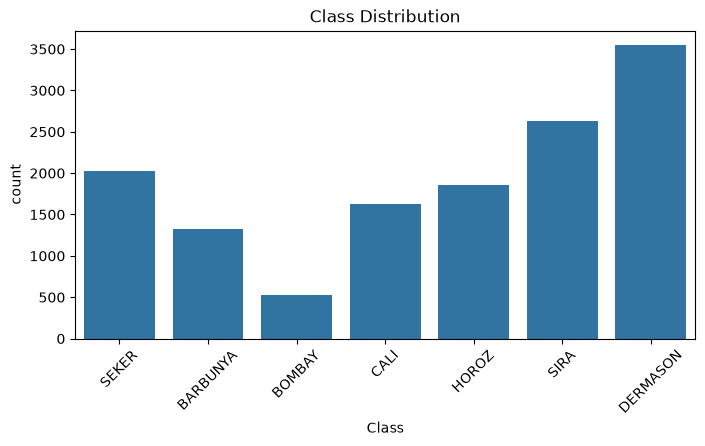

In [6]:
## Class Distribution

plt.figure(figsize=(8, 4))
sns.countplot(data=df, x="Class")
plt.title("Class Distribution")
plt.xticks(rotation=45)
plt.show()

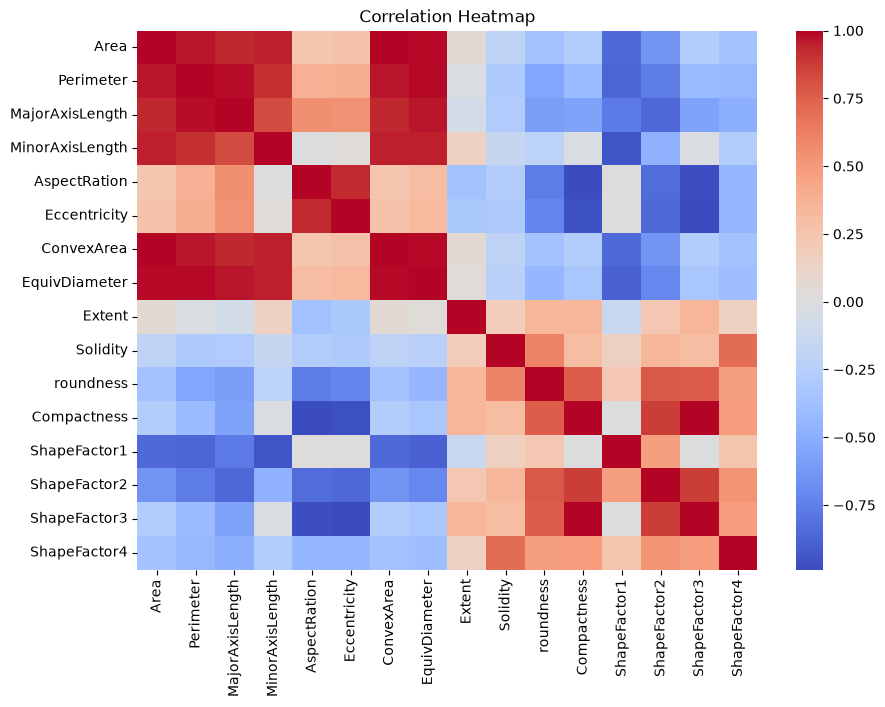

In [7]:
## Correlation Heatmap

plt.figure(figsize=(10, 7))
sns.heatmap(df.drop("Class", axis=1).corr(), cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

In [8]:
# Data Preprocessing
## Encode Target

encoder = LabelEncoder()
df["Class"] = encoder.fit_transform(df["Class"])

X = df.drop("Class", axis=1)
y = df["Class"]

print("Classes:", encoder.classes_)

Classes: ['BARBUNYA' 'BOMBAY' 'CALI' 'DERMASON' 'HOROZ' 'SEKER' 'SIRA']


In [9]:
## Train Test Split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (10834, 16)
Testing data: (2709, 16)


In [10]:
## Standardization

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [11]:
# Neural Network with Dropout & Batch Normalization
## Build Model

model = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(64, activation="relu", kernel_regularizer=l2(0.001)),
    BatchNormalization(),
    Dropout(0.30),
    Dense(32, activation="relu", kernel_regularizer=l2(0.001)),
    BatchNormalization(),
    Dropout(0.30),
    Dense(16, activation="relu"),
    Dropout(0.20),
    Dense(len(encoder.classes_), activation="softmax")
])

In [12]:
## Compile Model

model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 7)              │           119 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,199 (16.40 KB)

 Trainable params: 4,007 (15.65 KB)

 Non-trainable params: 192 (768.00 B)

In [13]:
## Train Model

history = model.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=128,
    validation_split=0.2,
    verbose=1
)

Epoch 1/20
68/68 ━━━━━━━━━━━━━━━━━━━━ 7s 18ms/step - accuracy: 0.5036 - loss: 1.4470 - val_accuracy: 0.7951 - val_loss: 1.2137
Epoch 2/20
68/68 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.7742 - loss: 0.7861 - val_accuracy: 0.8916 - val_loss: 0.6331
Epoch 3/20
68/68 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.8273 - loss: 0.6233 - val_accuracy: 0.9202 - val_loss: 0.4055
Epoch 4/20
68/68 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8492 - loss: 0.5443 - val_accuracy: 0.9202 - val_loss: 0.3280
Epoch 5/20
68/68 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.8667 - loss: 0.4978 - val_accuracy: 0.9229 - val_loss: 0.2935
Epoch 6/20
68/68 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8718 - loss: 0.4696 - val_accuracy: 0.9220 - val_loss: 0.2794
Epoch 7/20
68/68 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.8817 - loss: 0.4447 - val_accuracy: 0.9243 - val_loss: 0.2700
Epoch 8/20
68/68 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.8829 - loss: 0.4287 - val_accuracy: 0.9234 - val_los

In [14]:
# Evaluation

loss, accuracy = model.evaluate(X_test, y_test, verbose=0)
print("Test Accuracy:", accuracy)

y_prob = model.predict(X_test, verbose=0)
y_pred = y_prob.argmax(axis=1)

Test Accuracy: 0.921373188495636


In [15]:
## Classification Report

print(classification_report(y_test, y_pred, target_names=encoder.classes_))

              precision    recall  f1-score   support

    BARBUNYA       0.92      0.90      0.91       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.90      0.94      0.92       326
    DERMASON       0.93      0.91      0.92       709
       HOROZ       0.97      0.93      0.95       372
       SEKER       0.92      0.96      0.94       406
        SIRA       0.88      0.88      0.88       527

    accuracy                           0.92      2709
   macro avg       0.93      0.93      0.93      2709
weighted avg       0.92      0.92      0.92      2709



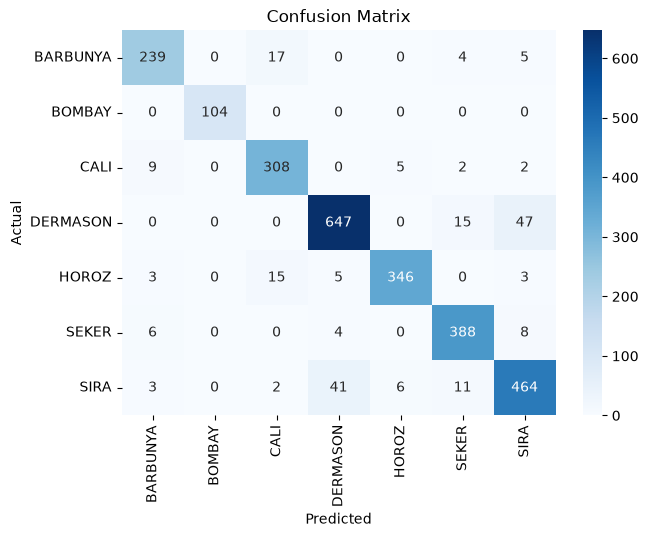

In [16]:
## Confusion Matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=encoder.classes_,
    yticklabels=encoder.classes_
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

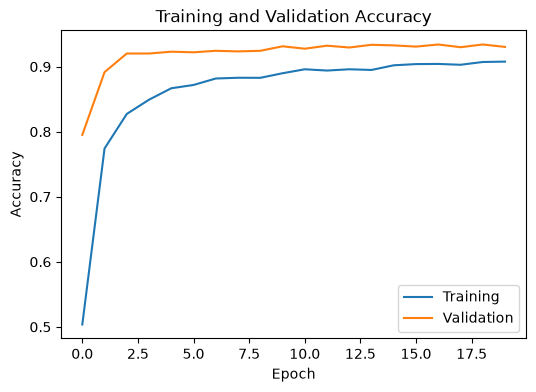

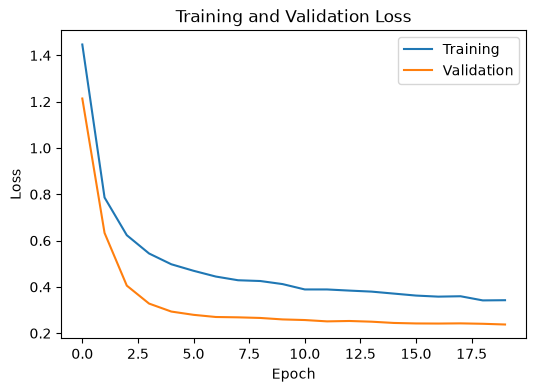

In [17]:
# Accuracy and Loss Graphs

plt.figure(figsize=(6, 4))
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.show()

plt.figure(figsize=(6, 4))
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.show()

In [18]:
# Optimizer Comparison

from tensorflow.keras.optimizers import RMSprop, SGD


def create_model(optimizer):
    optimizer_model = Sequential([
        Input(shape=(X_train.shape[1],)),
        Dense(64, activation="relu", kernel_regularizer=l2(0.001)),
        BatchNormalization(),
        Dropout(0.30),
        Dense(32, activation="relu", kernel_regularizer=l2(0.001)),
        BatchNormalization(),
        Dropout(0.30),
        Dense(16, activation="relu"),
        Dropout(0.20),
        Dense(len(encoder.classes_), activation="softmax")
    ])
    optimizer_model.compile(
        optimizer=optimizer,
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return optimizer_model


optimizers = {
    "Adam": Adam(learning_rate=0.001),
    "RMSprop": RMSprop(learning_rate=0.001),
    "SGD": SGD(learning_rate=0.01)
}

results = []

for name, optimizer in optimizers.items():
    optimizer_model = create_model(optimizer)
    optimizer_model.fit(
        X_train,
        y_train,
        epochs=10,
        batch_size=128,
        validation_split=0.2,
        verbose=0
    )
    optimizer_predictions = optimizer_model.predict(X_test, verbose=0).argmax(axis=1)
    results.append([name, accuracy_score(y_test, optimizer_predictions)])

result = pd.DataFrame(results, columns=["Optimizer", "Accuracy"])
result

,Optimizer,Accuracy
0,Adam,0.918789
1,RMSprop,0.915098
2,SGD,0.905869


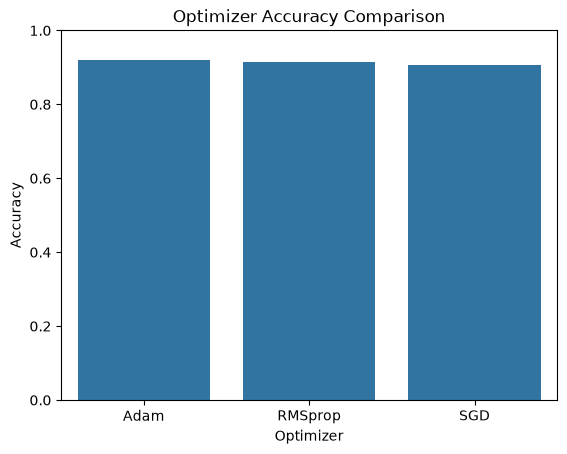

In [19]:
sns.barplot(data=result, x="Optimizer", y="Accuracy")
plt.title("Optimizer Accuracy Comparison")
plt.ylim(0, 1)
plt.show()